# 3. Bands, computation rate, timers and error messages

`examples/timers/` has equations in two bands: **1 Hz** and **10 Hz**. Bands are explicit frequencies with no required relationship. The engine tick rate is the least common multiple of all band frequencies, so every period is a whole number of ticks.

In [1]:
import sys, pathlib
try:
    import statesim
except ImportError:                      # not pip-installed: use the repo's src/ folder
    sys.path.insert(0, str(pathlib.Path("..").resolve() / "src"))
    import statesim
from statesim import load_model, Engine, ListTraceSink, FileTraceWriter, ModelError, EvaluationError
print("statesim imported")

statesim imported


In [2]:
from statesim.scheduler import build_schedule, due_items

model = load_model("../examples/timers/master.csv")
schedule = build_schedule(model)
print("tick rate:", model.tick_hz, "Hz")
for item in schedule:
    print(f"{item.name:<14} band={str(item.band_hz):>2} Hz  order={item.order}  period={item.period_ticks} ticks")

tick rate: 10 Hz
fast_2s        band=10 Hz  order=1  period=1 ticks
fast_dt_100    band=10 Hz  order=2  period=1 ticks
both_2s        band=10 Hz  order=3  period=1 ticks
sig_pos_10hz   band=10 Hz  order=4  period=1 ticks
slow_2s        band= 1 Hz  order=1  period=10 ticks
sig_pos_1hz    band= 1 Hz  order=2  period=10 ticks


## Computation rate
The engine runs on each tick exactly the items returned by `due_items`. A band runs on ticks where `(tick - 1) % period == 0`. Every band runs on tick 1. When several bands are due, the higher frequency runs first.

In [3]:
for tk in list(range(1, 4)) + list(range(10, 13)):
    print(f"tick {tk:>2}  t={(tk - 1) * 100:>5} ms :", [i.name for i in due_items(schedule, tk)])

tick  1  t=    0 ms : ['fast_2s', 'fast_dt_100', 'both_2s', 'sig_pos_10hz', 'slow_2s', 'sig_pos_1hz']
tick  2  t=  100 ms : ['fast_2s', 'fast_dt_100', 'both_2s', 'sig_pos_10hz']
tick  3  t=  200 ms : ['fast_2s', 'fast_dt_100', 'both_2s', 'sig_pos_10hz']
tick 10  t=  900 ms : ['fast_2s', 'fast_dt_100', 'both_2s', 'sig_pos_10hz']
tick 11  t= 1000 ms : ['fast_2s', 'fast_dt_100', 'both_2s', 'sig_pos_10hz', 'slow_2s', 'sig_pos_1hz']
tick 12  t= 1100 ms : ['fast_2s', 'fast_dt_100', 'both_2s', 'sig_pos_10hz']


Count the evaluations over 60 s of simulation. Each item runs exactly `band x 60` times. The evaluation instants are exact multiples of the period, with no drift. The requirement tests check this over long runs for equations and state machines (`tests/requirements/test_rate.py`).

In [4]:
from collections import Counter
from fractions import Fraction
ticks = int(60 * model.tick_hz)
runs = Counter()
last = {}
for tk in range(1, ticks + 1):
    for i in due_items(schedule, tk):
        runs[i.name] += 1
        last[i.name] = Fraction(tk - 1) * 1000 / model.tick_hz
for item in schedule:
    print(f"{item.name:<14} {runs[item.name]:>4} evaluations in 60 s, last at t = {last[item.name]} ms")

fast_2s         600 evaluations in 60 s, last at t = 59900 ms
fast_dt_100     600 evaluations in 60 s, last at t = 59900 ms
both_2s         600 evaluations in 60 s, last at t = 59900 ms
sig_pos_10hz    600 evaluations in 60 s, last at t = 59900 ms
slow_2s          60 evaluations in 60 s, last at t = 59000 ms
sig_pos_1hz      60 evaluations in 60 s, last at t = 59000 ms


## Continuous evaluation: a signal sampled at 1 Hz and at 10 Hz
The input `sig` is a 0.3 Hz sine written by Python before every tick. The same equation `sig > 0` runs in both bands. The 10 Hz result follows the signal closely. The 1 Hz result is only updated once per second and holds its value in between, so it can switch up to 1 s late. A 0.5 s pulse between two 1 Hz passes is never seen by the 1 Hz item.

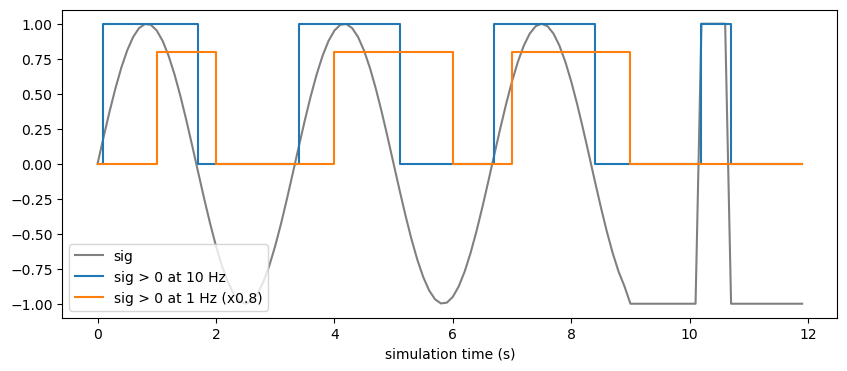

pulse seen at 10 Hz: True | seen at 1 Hz: False


In [5]:
import math
import matplotlib.pyplot as plt
eng = Engine(model)
rows = []
for tk in range(1, 121):                     # 12 s at 10 Hz
    tt = (tk - 1) / 10
    sig = math.sin(2 * math.pi * 0.3 * tt)
    if 10.2 <= tt < 10.7:                    # short pulse between 1 Hz passes (t = 10 s and 11 s)
        sig = 1.0
    elif tt >= 9.0:
        sig = -1.0
    eng.set_input("sig", sig)
    eng.step()
    o = eng.snapshot()["outputs"]
    rows.append((tt, sig, o["sig_pos_10hz"], o["sig_pos_1hz"]))
tt, sig, f10, f1 = zip(*rows)
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(tt, sig, label="sig", c="grey")
ax.step(tt, [v * 1.0 for v in f10], where="post", label="sig > 0 at 10 Hz")
ax.step(tt, [v * 0.8 for v in f1], where="post", label="sig > 0 at 1 Hz (x0.8)")
ax.set_xlabel("simulation time (s)"); ax.legend(loc="lower left"); plt.show()
print("pulse seen at 10 Hz:", any(r[2] for r in rows if 10.2 <= r[0] < 10.7),
      "| seen at 1 Hz:", any(r[3] for r in rows if r[0] >= 10.0))

## `t` and `dt`
`t` is absolute simulation time in ms (0 at the first run). `dt` is the ms since the item last ran (on its first run: its period). Both are available in any equation. A timer is just `t >= 2000`.

Both timers go true at the same simulation time (2000 ms), regardless of band.

In [6]:
eng = Engine(model)
print(f"{'tick':>4} {'t(ms)':>7}  slow_2s fast_2s fast_dt_100 both_2s")
for _ in range(25):
    eng.step()
    s = eng.snapshot()
    o = s["outputs"]
    print(f"{s['tick']:>4} {s['t']:>7.0f}  {str(o['slow_2s']):<7} {str(o['fast_2s']):<7} {str(o['fast_dt_100']):<11} {o['both_2s']}")

tick   t(ms)  slow_2s fast_2s fast_dt_100 both_2s
   1       0  False   False   True        False
   2     100  False   False   True        False
   3     200  False   False   True        False
   4     300  False   False   True        False
   5     400  False   False   True        False
   6     500  False   False   True        False
   7     600  False   False   True        False
   8     700  False   False   True        False
   9     800  False   False   True        False
  10     900  False   False   True        False
  11    1000  False   False   True        False
  12    1100  False   False   True        False
  13    1200  False   False   True        False
  14    1300  False   False   True        False
  15    1400  False   False   True        False
  16    1500  False   False   True        False
  17    1600  False   False   True        False
  18    1700  False   False   True        False
  19    1800  False   False   True        False
  20    1900  False   False   True    

Look at tick 21 (t = 2000 ms): `slow_2s` and `fast_2s` both become true, but `both_2s` (10 Hz band, reads `slow_2s`) only becomes true one tick later. The 10 Hz band is the higher frequency, so on a tick where both bands are due it runs first and still sees `slow_2s` from the previous pass.

## Execution order
Within a band, items run in their manual `order`. A later item sees an earlier item's result **in the same pass** (see `both_2s`, order 3, reading `fast_2s`, order 1). Higher-frequency bands run first when several are due on the same tick.

## Load errors
Problems in the CSVs raise `ModelError` with a `file:line` source. These fixtures are in `tests/fixtures/`.

In [7]:
for name in ("bad_syntax", "bad_no_default", "bad_mixed_band"):
    try:
        load_model(f"../tests/fixtures/{name}/master.csv")
    except ModelError as e:
        print(f"{name:<16} -> {e}")

bad_syntax       -> equations.csv:2: invalid expression 'not go and': invalid syntax
bad_no_default   -> M.csv:1: no default_state specified
bad_mixed_band   -> master.csv: cannot read file: No such file or directory


## Run-time errors
An undefined name is not checked at load time. It fails when evaluated, as an `EvaluationError` carrying the source, tick and item name.

In [8]:
import tempfile, pathlib
d = pathlib.Path(tempfile.mkdtemp())
(d / "master.csv").write_text("file_name,type,order\nequations.csv,equations,\n")
(d / "equations.csv").write_text(
    "equation,explanation,rationale,result_variable,band,order\n"
    "typo_name > 0,demo,demo,bad_eq,10,1\n")
eng = Engine(load_model(d / "master.csv"))
try:
    eng.step()
except EvaluationError as e:
    print("EvaluationError:", e)
    print("  source:", e.source, " tick:", e.tick, " item:", e.item)

EvaluationError: equations.csv:2: tick 1, bad_eq: NameError: name 'typo_name' is not defined
  source: equations.csv:2  tick: 1  item: bad_eq
